In [ ]:
import numpy as np
import torch
from torchvision import datasets, transforms
from matplotlib import pyplot as plt

import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

In [11]:
mnist_train = datasets.MNIST('./data', train=True, download=True, transform=transforms.ToTensor())
mnist_test = datasets.MNIST('./data', train=False, download=True, transform=transforms.ToTensor())

x_train = mnist_train.data.float() #/ 255.0  #NORMALIZATION HERE
t_train = mnist_train.targets
x_test = mnist_test.data.float() #/ 255.0 #NORMALIZATION HERE
t_test = mnist_test.targets

"""
#FLATTEN IF NEEDED
x_train = x_train.view(-1, 784)  # (60000, 784)
x_test = x_test.view(-1, 784)    # (10000, 784)
"""

print("x_train dim and type: ", x_train.shape, x_train.dtype)
print("t_train dim and type: ", t_train.shape, t_train.dtype)
print("x_test dim and type: ", x_test.shape, x_test.dtype)
print("t_test dim and type: ", t_test.shape, t_test.dtype)

x_train dim and type:  torch.Size([60000, 28, 28]) torch.float32
t_train dim and type:  torch.Size([60000]) torch.int64
x_test dim and type:  torch.Size([10000, 28, 28]) torch.float32
t_test dim and type:  torch.Size([10000]) torch.int64


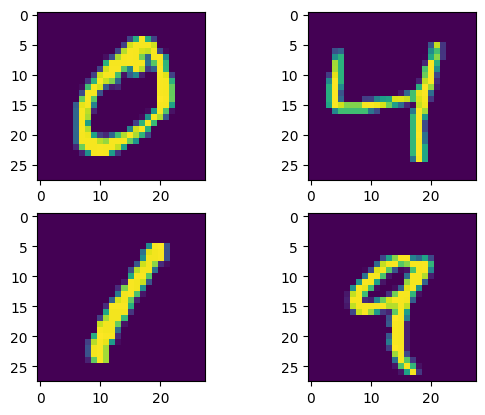

In [18]:
f, axarr = plt.subplots(2, 2)
axarr[0,0].imshow(x_train[1])
axarr[0,1].imshow(x_train[2])
axarr[1,0].imshow(x_train[3])
axarr[1,1].imshow(x_train[4])

In [19]:
use_cuda = True #switch if on cpu - im on google colab right now

use_cuda = use_cuda and torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu");
torch.manual_seed(1);

In [22]:
def permute_mnist(mnist, seed):
    np.random.seed(seed)
    h = w = 28
    perm_inds = list(range(h*w))
    np.random.shuffle(perm_inds)

    perm_mnist = []
    for set in mnist:
        num_img = set.shape[0]
        flat_set = set.reshape(num_img, w * h)
        perm_mnist.append(flat_set[:, perm_inds].reshape(num_img, w, h))
    return perm_mnist

x_train_perm, x_test_perm = permute_mnist([x_train, x_test], seed=42)

print("x_train_perm:", x_train_perm.shape)
print("x_test_perm:", x_test_perm.shape)

x_train_perm: torch.Size([60000, 28, 28])
x_test_perm: torch.Size([10000, 28, 28])


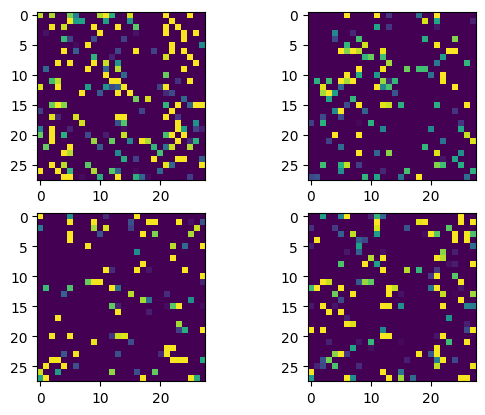

In [24]:
f, axarr = plt.subplots(2, 2)
axarr[0,0].imshow(x_train_perm[1])
axarr[0,1].imshow(x_train_perm[2])
axarr[1,0].imshow(x_train_perm[3])
axarr[1,1].imshow(x_train_perm[4])

In [27]:
def rotate_mnist(mnist, angle):
    print(f"starting rotation by {angle} degrees...")
    from scipy.ndimage import rotate

    rotated_mnist = []
    for set in mnist:
        num_img = set.shape[0]
        rotated_set = np.zeros_like(set)

        for i in range(num_img):
            rotated_set[i] = rotate(set[i], angle, reshape=False, order=1)

        rotated_mnist.append(rotated_set)

    return rotated_mnist

x_train_rot, x_test_rot = rotate_mnist([x_train, x_test], angle=90)

print("x_train_rot:", x_train_rot.shape)
print("x_test_rot:", x_test_rot.shape)

starting rotation by 90 degrees...
x_train_rot: (60000, 28, 28)
x_test_rot: (10000, 28, 28)


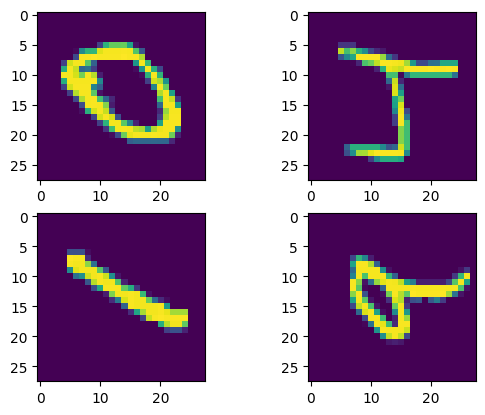

In [28]:
f, axarr = plt.subplots(2, 2)
axarr[0,0].imshow(x_train_rot[1])
axarr[0,1].imshow(x_train_rot[2])
axarr[1,0].imshow(x_train_rot[3])
axarr[1,1].imshow(x_train_rot[4])